# Data Science w Pythonie — Zajęcia 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_4.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_4/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.


## Grupowanie i łączenie danych

Na poprzednich zajęciach odsetek rezygnacji dla każdego typu karnetu liczyliśmy
tabelą krzyżową i obiecaliśmy, że da się prościej. Da się — i to jest pierwsza
połowa dzisiejszych zajęć: **grupowanie**, czyli liczenie czegokolwiek osobno
dla każdej grupy. Średnia w każdym mieście, mediana w każdym karnecie, liczba
klientów w każdej kombinacji jednego i drugiego.

Druga połowa wynika z prostego faktu: w prawdziwej firmie dane prawie nigdy nie
leżą w jednej tabeli. Klienci są w jednym systemie, zgłoszenia w drugim, kluby
w trzecim. Żeby cokolwiek z nimi zrobić, trzeba je najpierw **połączyć** po
wspólnej kolumnie — i nie zgubić ani nie rozmnożyć przy tym połowy wierszy.

Po dzisiejszych zajęciach będziesz w stanie:

- policzyć statystykę w grupach `groupby` i wyjaśnić schemat „podziel — policz
  — złóż",
- policzyć kilka statystyk naraz `agg` i nadać wynikom czytelne nazwy,
- pogrupować dane po dwóch kolumnach i rozłożyć wynik w tabelę `unstack`,
- połączyć dwie tabele `merge` i dobrać rodzaj złączenia (`left`, `inner`,
  `right`, `outer`),
- połączyć tabelę klientów z tabelą zdarzeń: najpierw `groupby`, potem
  `merge`, i sprawdzić, czy liczba wierszy się zgadza.

> ℹ️ **Gdzie jesteśmy**
>
> W workflow projektu z pierwszych zajęć to wciąż przygotowanie danych —
> zbieranie ich z kilku źródeł w jedną tabelę, z którą da się pracować.
> Ćwiczymy na siłowni, w zadaniu wracamy do MeritoBanku. Za godzinę na
> [Uczeniu głębokim](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_4/) dane kredytowe trafią do
> pierwszego sztucznego neuronu.


## Plan na dziś

| Blok | Czas |
|---|---|
| Podziel — policz — złóż: pierwszy `groupby` | 10 min |
| Kilka statystyk naraz i grupowanie po dwóch kolumnach | 12 min |
| Dane w kilku tabelach — `merge` | 12 min |
| Jeden-do-wielu: najpierw `groupby`, potem `merge` | 8 min |
| Ściągawka | 3 min |
| **Zadanie 4** | **45 min** |


## Grupowanie

### Dane, na których pracujemy

Znowu siłownia — ta sama wyczyszczona wersja co na zajęciach 3:

In [1]:
import pandas as pd

URL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/dane/silownia_czyste.csv"
df = pd.read_csv(URL)
df.head()

,klient_id,wiek,miasto,typ_karnetu,oplata_mies,staz_mies,wizyty_mies,zgloszenia,zrezygnowal
0,K1342,45,Gdańsk,Basic,99.0,20,1.2,0,1
1,K0802,34,Poznań,Standard,119.0,17,7.6,1,0
2,K0240,34,Warszawa,Basic,99.0,5,5.1,1,0
3,K0144,46,Poznań,Basic,99.0,52,2.4,0,0
4,K0619,48,Wrocław,Basic,99.0,52,6.1,1,0


### Podziel — policz — złóż

Pytanie z poprzednich zajęć: jaki jest odsetek rezygnacji w każdym typie
karnetu? Z `groupby` to jedna linijka:

In [2]:
df.groupby("typ_karnetu")["zrezygnowal"].mean()

typ_karnetu
Basic       0.190551
Premium     0.336570
Standard    0.229630
Name: zrezygnowal, dtype: float64

Te same liczby co w kolumnie `1` tabeli krzyżowej z zajęć 3. Czyta się to od
lewej do prawej, dokładnie w kolejności, w jakiej pandas wykonuje pracę:

```text
df.groupby("typ_karnetu")     ["zrezygnowal"]        .mean()
        PODZIEL               na której kolumnie        POLICZ        → ZŁÓŻ w jedną tabelę

 Basic    → 635 klientów  → 1, 0, 0, 0, 1, …    → średnia 0.191 ┐
 Premium  → 309 klientów  → 0, 1, 1, 0, 0, …    → średnia 0.337 ├→ wynik
 Standard → 540 klientów  → 0, 0, 1, 0, 0, …    → średnia 0.230 ┘
```

Ten schemat (*split — apply — combine*) jest wszędzie: tabele przestawne
w Excelu, `GROUP BY` w SQL, raporty w każdej firmie. Zmieniasz tylko kolumnę
grupującą, kolumnę liczoną i statystykę:

In [3]:
df.groupby("miasto")["wizyty_mies"].median()

miasto
Gdańsk      5.70
Kraków      6.05
Poznań      6.10
Warszawa    5.90
Wrocław     5.30
Name: wizyty_mies, dtype: float64

Zamiast `mean` i `median` możesz użyć każdej statystyki, którą znasz:
`sum`, `min`, `max`, `std`, `count`. Jedna jest szczególna — **ile wierszy jest
w każdej grupie** — i nie potrzebuje kolumny:

In [4]:
df.groupby("miasto").size()

miasto
Gdańsk      215
Kraków      290
Poznań      204
Warszawa    564
Wrocław     211
dtype: int64

To samo co `df["miasto"].value_counts()`, tylko posortowane alfabetycznie,
a nie od największej grupy.

### Wynik grupowania to zwykła seria

Wynik `groupby` to seria (albo DataFrame), więc działa na nim wszystko, co już
znasz — sortowanie, zaokrąglanie, wykresy:

In [5]:
df.groupby("miasto")["zrezygnowal"].mean().sort_values(ascending=False).round(3)

miasto
Warszawa    0.254
Wrocław     0.251
Kraków      0.245
Gdańsk      0.209
Poznań      0.181
Name: zrezygnowal, dtype: float64

Poznań trzyma klientów najlepiej, Warszawa — najgorzej. Nazwy miast trafiły do
**indeksu** (to te pogrubione etykiety po lewej). Jeśli wolisz je mieć w zwykłej
kolumnie — np. żeby potem połączyć tabelę z inną — dopisz `.reset_index()`.


## Kilka statystyk naraz

### `agg` — raport w jednej tabeli

Zwykle chcesz o każdej grupie wiedzieć kilka rzeczy jednocześnie. Do tego służy
`agg` z **nazwanymi agregacjami** — każda linijka to
`nazwa_w_wyniku=("kolumna", "statystyka")`:

In [6]:
raport = df.groupby("typ_karnetu").agg(
    klienci=("klient_id", "count"),
    odsetek_rezygnacji=("zrezygnowal", "mean"),
    srednia_oplata=("oplata_mies", "mean"),
    mediana_wizyt=("wizyty_mies", "median"),
)
raport.round(2)

,klienci,odsetek_rezygnacji,srednia_oplata,mediana_wizyt
typ_karnetu,,,,
Basic,635,0.19,94.80,6.1
Premium,309,0.34,195.57,5.8
Standard,540,0.23,135.17,5.6


Jedna tabela, którą można wkleić do raportu. Kolumna `klienci` jest tu nie bez
powodu — o tym za chwilę.

### Grupowanie po dwóch kolumnach

Czy Premium jest problemem w każdym mieście, czy tylko w niektórych? Podajemy
**listę** kolumn grupujących:

In [7]:
df.groupby(["miasto", "typ_karnetu"])["zrezygnowal"].mean().round(2)

miasto    typ_karnetu
Gdańsk    Basic          0.14
          Premium        0.31
          Standard       0.20
Kraków    Basic          0.19
          Premium        0.34
          Standard       0.24
Poznań    Basic          0.18
          Premium        0.17
          Standard       0.18
Warszawa  Basic          0.21
          Premium        0.37
          Standard       0.25
Wrocław   Basic          0.19
          Premium        0.43
          Standard       0.25
Name: zrezygnowal, dtype: float64

Wyszło 15 wierszy w długiej kolumnie — mało czytelne. `unstack()` przenosi
drugi poziom grupowania do kolumn i robi z wyniku tabelę:

In [8]:
odsetek = df.groupby(["miasto", "typ_karnetu"])["zrezygnowal"].mean().unstack()
odsetek.round(2)

typ_karnetu,Basic,Premium,Standard
miasto,,,
Gdańsk,0.14,0.31,0.20
Kraków,0.19,0.34,0.24
Poznań,0.18,0.17,0.18
Warszawa,0.21,0.37,0.25
Wrocław,0.19,0.43,0.25


Ciekawe: w Poznaniu Premium wcale nie odstaje (0.17), a we Wrocławiu odchodzi
prawie co drugi klient Premium (0.43). Zanim jednak ogłosisz to zarządowi,
sprawdź, **ilu klientów** stoi za każdą liczbą:

In [9]:
df.groupby(["miasto", "typ_karnetu"]).size().unstack()

typ_karnetu,Basic,Premium,Standard
miasto,,,
Gdańsk,71,55,89
Kraków,111,67,112
Poznań,98,35,71
Warszawa,252,117,195
Wrocław,103,35,73


Obie skrajne wartości — 0.17 w Poznaniu i 0.43 we Wrocławiu — policzone są
z **35 osób**. Pięciu klientów więcej albo mniej i odsetek przesuwa się o 14
punktów procentowych. To może być prawdziwa różnica, a może przypadek.

> ⚠️ **Mała grupa, duże liczby**
>
> Im mniejsza grupa, tym bardziej skrajne wyniki. Odsetek 100% z dwóch osób
> nie znaczy nic. Dlatego do **każdej** średniej czy odsetka w grupach dokładaj
> liczebność grupy — choćby jako `klienci=("klient_id", "count")` w `agg`.
> Grupy poniżej kilkudziesięciu obserwacji opisuj ostrożnie.

### Grupowanie po przedziałach

Kolumny liczbowej o wielu wartościach (np. staż w miesiącach) nie grupuje się
bezpośrednio — wyszłoby 60 grup po kilkanaście osób. Najpierw tniesz ją na
przedziały `pd.cut`, a potem grupujesz po przedziałach. `agg` z listą nazw
statystyk to krótsza wersja, gdy nie potrzebujesz własnych nazw kolumn:

In [10]:
przedzialy = pd.cut(df["staz_mies"], bins=[0, 6, 12, 24, 60])
df.groupby(przedzialy, observed=True)["zrezygnowal"].agg(["count", "mean"]).round(3)

,count,mean
staz_mies,,
"(0, 6]",141,0.397
"(6, 12]",140,0.364
"(12, 24]",278,0.309
"(24, 60]",925,0.169


Prawie 40% nowych klientów odchodzi w pierwszym półroczu, a z tych, którzy
wytrwali dwa lata — tylko 17%. `(0, 6]` czytaj „powyżej 0, do 6 włącznie".
`observed=True` każe pokazać tylko przedziały, w których ktoś jest.


## Dane w kilku tabelach

### Słownik klubów

Dział nieruchomości prowadzi własną tabelę — po jednym wierszu na klub:

In [11]:
URL_KLUBY = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/dane/kluby_2026.csv"
kluby = pd.read_csv(URL_KLUBY)
kluby

,miasto,klub,rok_otwarcia,metraz_m2,otwarty_24h
0,Warszawa,Merito Fit Centrum,2018,1800,tak
1,Kraków,Merito Fit Kazimierz,2020,1100,nie
2,Gdańsk,Merito Fit Oliwa,2021,900,tak
3,Wrocław,Merito Fit Rynek,2019,1000,nie
4,Poznań,Merito Fit Jeżyce,2022,750,nie
5,Łódź,Merito Fit Manufaktura,2026,1200,tak


Obie tabele mają kolumnę `miasto` — to jest **klucz**, po którym je połączymy.
Każdy klient ma jedno miasto, każde miasto ma jeden klub, więc każdemu
klientowi dopisujemy informacje o jego klubie:

In [12]:
pelne = df.merge(kluby, on="miasto", how="left")
print(df.shape, "→", pelne.shape)
pelne[["klient_id", "miasto", "klub", "otwarty_24h"]].head(3)

(1484, 9) → (1484, 13)


,klient_id,miasto,klub,otwarty_24h
0,K1342,Gdańsk,Merito Fit Oliwa,tak
1,K0802,Poznań,Merito Fit Jeżyce,nie
2,K0240,Warszawa,Merito Fit Centrum,tak


Wierszy tyle samo, kolumn o cztery więcej — dokładnie to, czego chcieliśmy.
Teraz można grupować po cechach klubu, których w tabeli klientów w ogóle nie
było:

In [13]:
pelne.groupby("otwarty_24h")[["wizyty_mies", "zrezygnowal"]].mean().round(3)

,wizyty_mies,zrezygnowal
otwarty_24h,,
nie,6.559,0.228
tak,6.534,0.241


Kluby całodobowe nie przyciągają częściej i nie trzymają klientów lepiej.
Brak różnicy to też wynik — dział nieruchomości właśnie się dowiedział, że
dopłacanie do nocnych zmian nie przekłada się na lojalność.

### Rodzaje złączeń

Zwróć uwagę na Łódź. Klub otwarto w tym roku i nie ma jeszcze żadnego klienta
w naszej tabeli. Co się z nim stanie, zależy od parametru `how`:

| `how=` | Co zostaje | Tu |
|---|---|---|
| `"left"` | wszystkie wiersze z **lewej** tabeli (`df`); brakujące dane z prawej → `NaN` | 1484 — Łódź znika |
| `"inner"` | tylko wiersze, których klucz jest **w obu** tabelach | 1484 — Łódź znika |
| `"right"` | wszystkie wiersze z **prawej** tabeli (`kluby`) | 1485 — Łódź z `NaN` w danych klienta |
| `"outer"` | wszystko z obu tabel | 1485 |

Domyślnie `merge` robi `inner`. W praktyce najczęściej chcesz `left`: masz
główną tabelę (klientów, kredyty, zamówienia) i dokładasz do niej informacje
z innych tabel, **nie gubiąc** żadnego wiersza głównej. Tu `left` i `inner`
dały ten sam wynik, bo każde miasto klienta jest w słowniku klubów — ale to
szczęście, nie reguła.

> 💡 **Klucz nazywa się inaczej w każdej tabeli?**
>
> Gdy w jednej tabeli kolumna to `miasto`, a w drugiej `lokalizacja`, użyj
> `df.merge(kluby, left_on="miasto", right_on="lokalizacja", how="left")`.
> A jeśli klucz to np. `"Kraków"` w jednej i `"KRAKÓW "` w drugiej — wracasz do
> ujednolicania tekstu z zajęć 2. `merge` porównuje wartości co do znaku.


## Jeden-do-wielu

### Dziennik zgłoszeń

System obsługi klienta zapisuje każde zgłoszenie jako osobny wiersz:

In [14]:
URL_ZGL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/dane/zgloszenia_2026.csv"
zgl = pd.read_csv(URL_ZGL)
print(zgl.shape)
zgl.head()

(1201, 4)


,zgloszenie_id,klient_id,data,kategoria
0,Z0001,K1115,2026-01-02,sprzęt
1,Z0002,K0249,2026-01-03,tłok
2,Z0003,K0367,2026-01-03,tłok
3,Z0004,K0446,2026-01-03,sprzęt
4,Z0005,K0564,2026-01-03,tłok


Tu relacja jest inna niż z klubami: **jeden klient może mieć wiele zgłoszeń**
— albo żadnego. Co się stanie, jeśli połączymy tabele wprost?

In [15]:
df.merge(zgl, on="klient_id").shape

(1201, 12)

Zamiast 1484 klientów mamy 1201 wierszy. Klient z trzema zgłoszeniami pojawił
się trzy razy, a 663 klientów bez zgłoszeń zniknęło (domyślne `inner`). Każda
średnia policzona na takiej tabeli będzie przekłamana — klienci, którzy dużo
narzekają, liczą się kilka razy.

> ⛔ **Zawsze sprawdzaj `shape` przed i po `merge`**
>
> Jeśli łączysz tabelę klientów z czymkolwiek i liczba wierszy **wzrosła**,
> klucz w drugiej tabeli się powtarza. Jeśli **spadła** — część kluczy nie
> znalazła pary. Ani jedno, ani drugie nie wywoła błędu. pandas grzecznie
> zrobi to, o co go poprosiłeś, a przekłamany wynik zobaczysz dopiero
> w raporcie.

### Najpierw `groupby`, potem `merge`

Właściwa kolejność: najpierw **streszczamy** tabelę zdarzeń do jednego wiersza
na klienta, a dopiero potem łączymy:

In [16]:
na_klienta = zgl.groupby("klient_id").size().reset_index(name="liczba_zgloszen")
print(na_klienta.shape)
na_klienta.head(3)

(821, 2)


,klient_id,liczba_zgloszen
0,K0005,2
1,K0006,1
2,K0007,2


`reset_index(name=...)` zamienia indeks z identyfikatorami na zwykłą kolumnę
i nazywa kolumnę z wynikiem. Teraz łączymy — `left`, żeby nie zgubić klientów
bez zgłoszeń:

In [17]:
df2 = df.merge(na_klienta, on="klient_id", how="left")
print(df2.shape)
print("brak zgłoszeń (NaN):", df2["liczba_zgloszen"].isna().sum())

(1484, 10)
brak zgłoszeń (NaN): 663


Klient, którego nie ma w dzienniku, dostał `NaN`. Ale tu brak znaczy coś
konkretnego — **zero zgłoszeń** — więc uzupełniamy zerem, nie medianą:

In [18]:
df2["liczba_zgloszen"] = df2["liczba_zgloszen"].fillna(0).astype(int)
print((df2["liczba_zgloszen"] == df2["zgloszenia"]).all())

True


Wynik zgadza się co do klienta z kolumną `zgloszenia`. Teraz już wiesz, skąd
ona się wzięła — ktoś przed Tobą zrobił dokładnie te trzy kroki.

### Nowa informacja z tabeli zdarzeń

Dziennik ma coś, czego w tabeli klientów nie było: **kategorię** zgłoszenia.
Dopiszmy do każdego zgłoszenia informację, czy klient odszedł, i pogrupujmy po
kategorii:

In [19]:
z = zgl.merge(df[["klient_id", "zrezygnowal"]], on="klient_id", how="left")

z.groupby("kategoria")["zrezygnowal"].agg(["count", "mean"]).sort_values("mean").round(3)

,count,mean
kategoria,,
sprzęt,305,0.193
czystość,268,0.243
tłok,283,0.300
obsługa,197,0.462
płatności,148,0.493


Tym razem lewą tabelą są zgłoszenia, więc 1201 wierszy to dokładnie to, czego
chcemy — jeden wiersz na zgłoszenie. A wniosek jest konkretny: na sprzęt
narzekają ci, którzy chodzą, a na obsługę i płatności — ci, którzy zaraz
odejdą. Prawie połowa klientów ze zgłoszeniem o płatnościach zrezygnowała.

Text(0, 0.5, 'kategoria zgłoszenia')

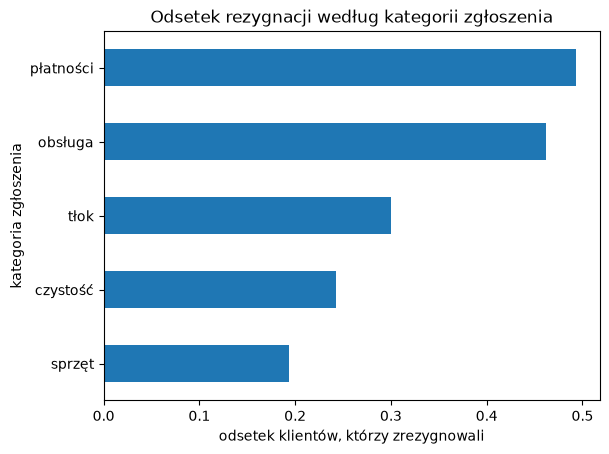

In [20]:
import matplotlib.pyplot as plt

z.groupby("kategoria")["zrezygnowal"].mean().sort_values().plot(
    kind="barh", title="Odsetek rezygnacji według kategorii zgłoszenia")
plt.xlabel("odsetek klientów, którzy zrezygnowali")
plt.ylabel("kategoria zgłoszenia")

Gdyby ktoś zostawił tylko kolumnę `zgloszenia` z samą liczbą, tej informacji
by nie było. Dlatego dane zbiera się z tabel źródłowych, a nie tylko z gotowych
podsumowań.

> 📝 **A sklejanie tabel jedna pod drugą?**
>
> `merge` dokleja kolumny **obok** po kluczu. Czasem potrzebujesz czegoś
> innego — np. masz zgłoszenia z każdego miesiąca w osobnym pliku i chcesz je
> ułożyć **jedno pod drugim**. Do tego służy
> `pd.concat([styczen, luty, marzec], ignore_index=True)`. Tabele muszą mieć
> te same kolumny.


## Ściągawka

| Chcę… | Kod |
|---|---|
| statystykę w grupach | `df.groupby("grupa")["kol"].mean()` |
| liczbę wierszy w grupach | `df.groupby("grupa").size()` |
| kilka statystyk z nazwami | `df.groupby("grupa").agg(ile=("id", "count"), srednia=("kol", "mean"))` |
| kilka statystyk bez nazw | `df.groupby("grupa")["kol"].agg(["count", "mean"])` |
| grupować po dwóch kolumnach | `df.groupby(["a", "b"])["kol"].mean()` |
| rozłożyć wynik w tabelę | `... .unstack()` |
| grupy z indeksu do kolumny | `... .reset_index()` albo `... .reset_index(name="nazwa")` |
| grupować po przedziałach | `df.groupby(pd.cut(df["kol"], bins=[0, 6, 12, 60]), observed=True)` |
| dołączyć kolumny z innej tabeli | `df.merge(inna, on="klucz", how="left")` |
| klucz o innej nazwie | `df.merge(inna, left_on="a", right_on="b", how="left")` |
| tabela zdarzeń → jeden wiersz na klienta | `zdarzenia.groupby("klient_id").agg(...).reset_index()` |
| brak zdarzeń = zero | `df["kol"] = df["kol"].fillna(0)` |
| sprawdzić, czy merge nic nie zepsuł | `print(df.shape, wynik.shape)` |
| skleić tabele jedna pod drugą | `pd.concat([t1, t2], ignore_index=True)` |

## Zadanie 4

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_4/#zadanie-4-trzy-systemy-jeden-klient-6-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.